In [1]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))

# Now import Model from freeflux

import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import analysis.io_func as io_func
from matplotlib import ticker
## notebook where we just load previously generated csv (sampled data + weights) and plot the global flux range (va + sampling)


### In the previous notebooks, we got samples from the flux space that are feasible in the thermodynamically-stoichio constrained drG space using PTA
### Here, we get the DRG samples and look at the trace plots

In [2]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [3]:
from analysis import config_pta as cfp
 ##flux bounds  
cond='TM6'

prep=cfp.config_prep(cond)

/home/nathan/anaconda3/envs/pta/lib/python3.10/site-packages/enkie/compartment_parameters.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Set parameter Username
Set parameter LicenseID to value 2749904
Set parameter GURO_PAR_DUMP to value 1
Read parameters from file gurobi.env
Academic license - for non-commercial use only - expires 2026-12-04
removing ['Galkin', 'Gal7', 'Gal10', 'Mankin', 'M6pism', 'MALTGD', 'gal-D_EX', 'man-D_EX', 'malt_EX', 'GALt+0', 'Mant+0', 'MALTt+1']
no met data for ppi_c 'ppi'
no met data for 4pasp_c '4pasp'
no met data for oaa_c 'oaa'
no met data for oaa_m 'oaa'
no met data for nadph_c 'nadph'
no met data for aspsa_c 'aspsa'
no met data for pi_c 'pi'
no met data for pyr_c 'pyr'
no met data for pyr_m 'pyr'
no met data for glycogen_c 'glycogen'
no met data for g1p_c 'g1p'
no met data for glx_c 'glx'
no met data for hco3_m 'hco3'
nadph_m ignored because we set constraint on redox ratio
no met data for hco3_c 'hco3'
no met data for acglu_m 'acglu'
no met data for acg5p_m 'acg5p'
no met data for acg5sa_m 'acg5sa'
no met data for acorn_m 'acorn'
no met data for argsuc_c 'argsuc'
no met data for arg-L_

load drG  samples

in usr folder bc lot of memory 

In [4]:
folder='/usr/PhD/2601_13C/'
drgsamples=pd.read_feather(f'{folder}/{cond}_samples.feather')


In [8]:
# traceplot(ax,marginals)
def _traceplot(ax,marginal,rxn_index=None,label=None):
    ##pick a random reaction and plot its value as a line across time
    rxn_rand=np.random.choice(marginal.columns) if rxn_index is None else rxn_index
    ax.plot(marginal[rxn_rand],label=label,alpha=1)
    return rxn_rand
from math import ceil

def traceplots(axes,marginal_list,nplots,r_ids=None,labels=None):
    # axes=axes.flatten()
    def _trace(axes,marginal,nplots,r_ids=None,label=None):
        for i in range(nplots):
            rxn_rand =_traceplot(axes[i],marginal) if r_ids is None else _traceplot(axes[i],marginal,r_ids[i],label=label) 
            axes[i].set_title(f"Reaction {rxn_rand}",fontsize=12)
    for i,marginal in enumerate(marginal_list):
        _trace(axes,marginal,nplots,r_ids,labels[i])

['PYRt-1+H' 'ARGSS' 'HICITDm']


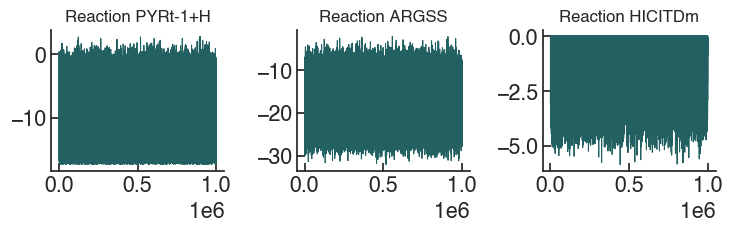

In [9]:
nplots=3
nrows=ceil(nplots/3) if nplots>3 else 1
fig,axes=plt.subplots(nrows,3,figsize=(7.5,2.5),layout='tight')
io_func.scale_rcparams(fig)
axes=axes.flatten()
## generate 3 random numbers
random_rxns=np.random.choice(drgsamples.columns,nplots)
print(random_rxns)
# r_index=[27,  192 ,136]

traceplots(axes,[drgsamples],nplots,r_ids=random_rxns,#[200,220,240],
           labels=['Trace 1','Trace 2','Trace3'])
for ax in axes:
    ax.autoscale()
    ax.locator_params(axis='both',nbins=3)
    # io_func.rescale_ylim(ax)
    #format ticks
    # ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:.2e}"))
# axes[1].legend(edgecolor='black')

autocorr plots

In [10]:
# def autocorrplot(ax,marginal,rxn_index=None,label=None): if not rxn_index: rxn_rand=np.random.randint(0,281) else : rxn_rand=rxn_index pd.plotting.autocorrelation_plot(pd.Series(marginal[rxn_rand]),ax=ax,label=label) # ax.acorr(marginal[rxn_rand],maxlags=1000) return rxn_rand def autocorrplots(marginal,nplots,r_idx=None): nrows=ceil(nplots/3) if nplots>3 else 1 fig,axes=plt.subplots(nrows,3,figsize=(14,5),layout='tight') axes=axes.flatten() for i in range(nplots): rxn_rand = autocorrplot(axes[i],marginal,r_idx[i]) if r_idx else autocorrplot(axes[i],marginal) axes[i].set_title(f"Reaction {cmodel.reactions[rxn_rand].id}")

In [11]:
# single autocorrelation plot
def _autocorrplot(ax, marginal, rxn_index=None, label=None):

    # choose random reaction column if none provided
    rxn_rand = np.random.choice(marginal.columns) if rxn_index is None else rxn_index

    pd.plotting.autocorrelation_plot(
        pd.Series(marginal[rxn_rand]),
        ax=ax,
        # label=label
    )

    return rxn_rand


def autocorrplots(axes, marginal_list, nplots, r_ids=None, labels=None):

    def _autocorr(axes, marginal, nplots, r_ids=None, label=None):

        for i in range(nplots):

            rxn_rand = (
                _autocorrplot(axes[i], marginal, label=label)
                if r_ids is None
                else _autocorrplot(axes[i], marginal, r_ids[i], label=label)
            )

            axes[i].set_title(f"Reaction {rxn_rand}", fontsize=12)

    for i, marginal in enumerate(marginal_list):

        _autocorr(
            axes,
            marginal,
            nplots,
            r_ids=r_ids,
            label=None if labels is None else labels[i]
        )

['CHORS' 'ACSm' 'PC']


Text(0, 0.5, 'Autocorrelation')

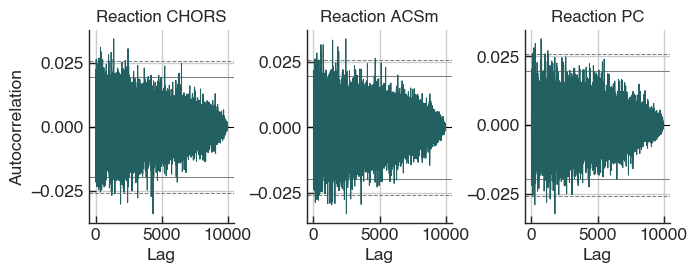

In [12]:
from math import ceil
import matplotlib.ticker as ticker

nplots = 3

nrows = ceil(nplots / 3) if nplots > 3 else 1

fig, axes = plt.subplots(
    nrows,
    3,
    figsize=(7.5, 2.5),

)
fig.subplots_adjust(wspace=0.5)

axes = axes.flatten()

# generate random reaction IDs
random_rxns = np.random.choice(drgsamples.columns, nplots)

print(random_rxns)

autocorrplots(
    axes,
    [drgsamples.iloc[:10000]],
    nplots,
    r_ids=random_rxns,
    labels=['Chain 1']
)

for ax in axes[:nplots]:

    ax.autoscale()

    ax.locator_params(axis='both', nbins=3)

    # format ticks
    # ax.yaxis.set_major_formatter(
    #     ticker.StrMethodFormatter("{x:.2e}")
    # )
    ax.set_ylabel('')

axes[0].set_ylabel('Autocorrelation')
# show legend on middle subplot
# axes[1].legend(edgecolor='black')

calc mixing for each r : step size /spread of the traceplot

In [13]:
mixing = (
    np.mean(np.abs(np.diff(drgsamples, axis=0)), axis=0)
    / np.std(drgsamples, axis=0)
)
mixing

ASNS1           1.128660
ASPK            0.998533
ASPTA           1.105259
ASPTAm          1.042582
ASAD            1.001568
                  ...   
PYRtm-1         1.129957
PYRtm-1+H       1.129957
SUCCPItm-2-2    1.127396
SUCFUMtm-2-2    1.103477
THRtm+0         1.098194
Length: 247, dtype: float64

In [17]:
mixing.describe()

count    247.000000
mean       1.095993
std        0.055103
min        0.847979
25%        1.083911
50%        1.126935
75%        1.129282
max        1.146803
dtype: float64

In [14]:
##how much are above 1
np.sum(mixing>1)/len(mixing)

0.9230769230769231

Text(0.5, 0, 'Normalized step size')

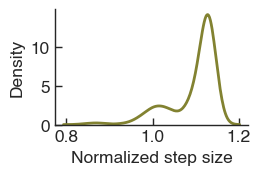

In [15]:
fig,ax = plt.subplots(figsize=(2.5,1.5))
sns.kdeplot(mixing,color=palette[2],linewidth=2)
ax.set_xlabel('Normalized step size')
##save fig 
# plt.savefig(f'{cfp.PLOTS_FOLDER}/../SuppFigures/202601_13C_{cond}_mixing.png',bbox_inches='tight',dpi=300)
# plt.savefig(f'{cfp.PLOTS_FOLDER}/../SuppFigures/202601_13C_{cond}_mixing.svg',bbox_inches='tight',dpi=300)
# plt.savefig(f'{cfp.PLOTS_FOLDER}/../SuppFigures/202601_13C_{cond}_mixing.pdf',bbox_inches='tight',dpi=300)


In [16]:
cond

'TM6'